<a href="https://colab.research.google.com/github/Eduard1298/M-todos-de-aprendizaje-no-supervisado/blob/main/M%C3%A9todos_de_aprendizaje_no_supervisado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 EJERCICIO: CLUSTERING CON K-MEANS - TRANSPORTE TUNJA

Total de viajes simulados: 350

Primeros 10 registros (distancia_km, tiempo_viaje_min):
   distancia_km  tiempo_viaje_min
0          1.05              19.8
1          1.12              13.5
2          1.95              36.0
3          1.48              21.6
4          4.42              36.4
5          1.64              23.1
6          0.50              11.4
7          1.83              20.5
8          2.55              28.9
9          0.89               6.5

Modelo K-Means entrenado con 3 grupos (clusters).

Cantidad de viajes por cluster:
cluster
0    137
1     72
2    141
Name: count, dtype: int64

Promedio de cada variable por cluster:
         distancia_km  tiempo_viaje_min  transbordo
cluster                                            
0                2.17             29.61        0.77
1                3.45             44.13        0.93
2                1.02             14.97        0.30

Interpretación (el modelo nunca vio l

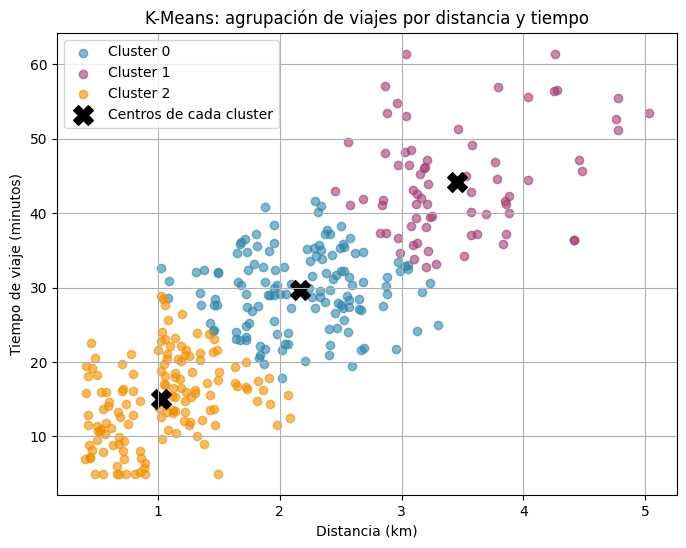

In [4]:
# ============================================================
# SISTEMA DE TRANSPORTE DE TUNJA
# EJERCICIO: CLUSTERING CON K-MEANS (NO SUPERVISADO)
# ============================================================
# Agrupamos viajes de bus según su distancia y su tiempo de
# viaje, sin decirle al modelo si el viaje fue directo o si
# tuvo transbordo. El modelo descubre los grupos por sí mismo,
# a partir de la similitud entre los datos.
# ============================================================

import random
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

print("==============================================")
print(" EJERCICIO: CLUSTERING CON K-MEANS - TRANSPORTE TUNJA")
print("==============================================")


# ============================================================
# 1. BASE DE CONOCIMIENTO (lugares y rutas del sistema)
# ============================================================

LUGARES = [
    "Arboleda", "Avenida Norte", "Terminal", "Cooservicios",
    "La Fuente", "Plaza de Bolívar", "ESE Santiago de Tunja",
    "Muiscas", "Triunfo", "Runta", "Avenida Oriental", "Nieves",
    "Uniboyacá", "Pirgua", "Estadio", "Retén Sur", "Asís",
    "Avenida Universitaria", "C.C. Viva", "San Francisco", "Florida"
]

RUTAS = {
    "R1": ["Arboleda", "Avenida Norte", "Terminal"],
    "R8": ["Cooservicios", "La Fuente", "Plaza de Bolívar", "Terminal", "ESE Santiago de Tunja"],
    "R9": ["Arboleda", "Avenida Norte", "La Fuente", "Avenida Universitaria"],
    "R10": ["Muiscas", "Avenida Norte", "Triunfo"],
    "R12": ["Runta", "Avenida Oriental", "Nieves", "Avenida Norte", "Muiscas", "Uniboyacá", "Plaza de Bolívar"],
    "R15": ["Cooservicios", "Avenida Norte", "Muiscas"],
    "R20": ["Pirgua", "Terminal", "Avenida Norte", "Arboleda"],
    "R21": ["Pirgua", "Terminal", "Estadio", "Retén Sur"],
    "R22": ["Asís", "Muiscas", "Avenida Universitaria", "C.C. Viva", "Terminal", "La Fuente"],
    "R23": ["Arboleda", "Uniboyacá", "Florida", "San Francisco"]
}

TIEMPOS_RUTA = {
    "R1": 15, "R8": 20, "R9": 20, "R10": 15, "R12": 30,
    "R15": 20, "R20": 20, "R21": 20, "R22": 25, "R23": 25
}

TIEMPO_TRANSBORDO = 5


def buscar_ruta_directa(origen, destino):
    for nombre_ruta, lugares in RUTAS.items():
        for sentido in [lugares, list(reversed(lugares))]:
            if origen in sentido and destino in sentido:
                p_origen = sentido.index(origen)
                p_destino = sentido.index(destino)
                if p_origen < p_destino:
                    return nombre_ruta, sentido[p_origen:p_destino + 1]
    return None


def buscar_ruta_con_transbordo(origen, destino):
    for ruta_1, lugares_1_o in RUTAS.items():
        for lugares_1 in [lugares_1_o, list(reversed(lugares_1_o))]:
            if origen not in lugares_1:
                continue
            p_origen = lugares_1.index(origen)

            for ruta_2, lugares_2_o in RUTAS.items():
                if ruta_1 == ruta_2:
                    continue
                for lugares_2 in [lugares_2_o, list(reversed(lugares_2_o))]:
                    if destino not in lugares_2:
                        continue
                    p_destino = lugares_2.index(destino)

                    for lugar in lugares_1:
                        if lugar not in lugares_2:
                            continue
                        p_t1 = lugares_1.index(lugar)
                        p_t2 = lugares_2.index(lugar)
                        if p_origen < p_t1 and p_t2 <= p_destino:
                            tramo_1 = lugares_1[p_origen:p_t1 + 1]
                            tramo_2 = lugares_2[p_t2:p_destino + 1]
                            return ruta_1, ruta_2, tramo_1, tramo_2
    return None


def simular_viaje(origen, destino):
    resultado = buscar_ruta_directa(origen, destino)

    if resultado:
        ruta, recorrido = resultado
        num_paradas = len(recorrido) - 1
        transbordo = 0
        tiempo_base = TIEMPOS_RUTA[ruta] * (num_paradas / (len(RUTAS[ruta]) - 1))
    else:
        resultado = buscar_ruta_con_transbordo(origen, destino)
        if not resultado:
            return None

        ruta_1, ruta_2, tramo_1, tramo_2 = resultado
        num_paradas = (len(tramo_1) - 1) + (len(tramo_2) - 1)
        transbordo = 1

        t1 = TIEMPOS_RUTA[ruta_1] * ((len(tramo_1) - 1) / (len(RUTAS[ruta_1]) - 1))
        t2 = TIEMPOS_RUTA[ruta_2] * ((len(tramo_2) - 1) / (len(RUTAS[ruta_2]) - 1))
        tiempo_base = t1 + t2 + TIEMPO_TRANSBORDO

    hora_pico = random.choices([0, 1], weights=[0.55, 0.45])[0]
    lluvia = random.choices([0, 1], weights=[0.65, 0.35])[0]

    distancia_km = round(max(0.3, num_paradas * 0.6 + random.uniform(-0.2, 0.3)), 2)

    efecto_hora_pico = random.uniform(5, 10) if hora_pico else 0
    efecto_lluvia = random.uniform(3, 7) if lluvia else 0
    ruido = random.gauss(0, 2.5)

    tiempo_viaje = max(5.0, round(tiempo_base + efecto_hora_pico + efecto_lluvia + ruido, 1))

    return [num_paradas, distancia_km, hora_pico, lluvia, transbordo, tiempo_viaje]


# ============================================================
# 2. PREPARACIÓN DE LOS DATOS (sin etiquetas)
# ============================================================
# A diferencia del aprendizaje supervisado, aquí NO le damos al
# modelo ninguna variable objetivo: solo le damos las
# características de cada viaje y dejamos que agrupe por sí
# mismo los que son parecidos entre sí.

random.seed(42)

filas = []
intentos = 0
while len(filas) < 350 and intentos < 350 * 20:
    intentos += 1
    origen, destino = random.choice(LUGARES), random.choice(LUGARES)
    if origen == destino:
        continue
    fila = simular_viaje(origen, destino)
    if fila:
        filas.append(fila)

columnas = ["num_paradas", "distancia_km", "hora_pico", "lluvia", "transbordo", "tiempo_viaje_min"]
datos = pd.DataFrame(filas, columns=columnas)

# Variables que usamos para agrupar: distancia y tiempo de viaje.
# No incluimos "transbordo" a propósito: queremos ver si el
# modelo lo "redescubre" solo, agrupando por similitud.
X = datos[["distancia_km", "tiempo_viaje_min"]]

print(f"\nTotal de viajes simulados: {len(X)}")
print("\nPrimeros 10 registros (distancia_km, tiempo_viaje_min):")
print(X.head(10))

# Escalamos las variables porque tienen rangos distintos
# (la distancia va de 0 a 5 km, el tiempo de 5 a 60 minutos).
# K-Means mide distancias, así que sin escalar el tiempo
# dominaría por completo el resultado.
escalador = StandardScaler()
X_escalado = escalador.fit_transform(X)


# ============================================================
# 3. CREACIÓN Y ENTRENAMIENTO DEL MODELO (No supervisado)
# ============================================================

NUM_GRUPOS = 3

modelo = KMeans(n_clusters=NUM_GRUPOS, random_state=42, n_init=10)
modelo.fit(X_escalado)

print(f"\nModelo K-Means entrenado con {NUM_GRUPOS} grupos (clusters).")

datos["cluster"] = modelo.labels_

print("\nCantidad de viajes por cluster:")
print(datos["cluster"].value_counts().sort_index())

print("\nPromedio de cada variable por cluster:")
print(datos.groupby("cluster")[["distancia_km", "tiempo_viaje_min", "transbordo"]].mean().round(2))


# ============================================================
# 4. INTERPRETACIÓN DE LOS GRUPOS
# ============================================================
# No le dimos "transbordo" al modelo, pero podemos comparar
# cada cluster contra esa variable real para ver si el modelo
# la redescubrió solo, agrupando por distancia y tiempo.

print("\nInterpretación (el modelo nunca vio la columna 'transbordo'):")
for cluster_id in sorted(datos["cluster"].unique()):
    grupo = datos[datos["cluster"] == cluster_id]
    print(
        f" - Cluster {cluster_id}: {len(grupo)} viajes | "
        f"distancia media {grupo['distancia_km'].mean():.2f} km | "
        f"tiempo medio {grupo['tiempo_viaje_min'].mean():.1f} min | "
        f"{grupo['transbordo'].mean() * 100:.0f}% con transbordo"
    )


# ============================================================
# 5. ASIGNAR UN VIAJE NUEVO A UN CLUSTER (Inferencia)
# ============================================================
# Un viaje nuevo: 2.0 km de distancia y 25 minutos de duración.

viaje_nuevo = pd.DataFrame({"distancia_km": [2.0], "tiempo_viaje_min": [25]})
viaje_nuevo_escalado = escalador.transform(viaje_nuevo)
cluster_nuevo = modelo.predict(viaje_nuevo_escalado)

print(f"\nUn viaje nuevo de 2.0 km y 25 minutos pertenece al cluster {cluster_nuevo[0]}.")


# ============================================================
# 6. VISUALIZACIÓN DE LOS RESULTADOS
# ============================================================

centros_escalados = modelo.cluster_centers_
centros_reales = escalador.inverse_transform(centros_escalados)

plt.figure(figsize=(8, 6))
colores = ["#2E86AB", "#A23B72", "#F18F01"]

for cluster_id in range(NUM_GRUPOS):
    grupo = datos[datos["cluster"] == cluster_id]
    plt.scatter(
        grupo["distancia_km"], grupo["tiempo_viaje_min"],
        color=colores[cluster_id], alpha=0.6, label=f"Cluster {cluster_id}"
    )

plt.scatter(
    centros_reales[:, 0], centros_reales[:, 1],
    color="black", marker="X", s=200, label="Centros de cada cluster"
)

plt.title("K-Means: agrupación de viajes por distancia y tiempo")
plt.xlabel("Distancia (km)")
plt.ylabel("Tiempo de viaje (minutos)")
plt.legend()
plt.grid(True)
plt.show()

